<a href="https://colab.research.google.com/github/amritpaxt/APIx_DYNAMIS/blob/main/RNN1.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

Day 20 actual sales: 250.0
Day 21 predicted sales: 186.65


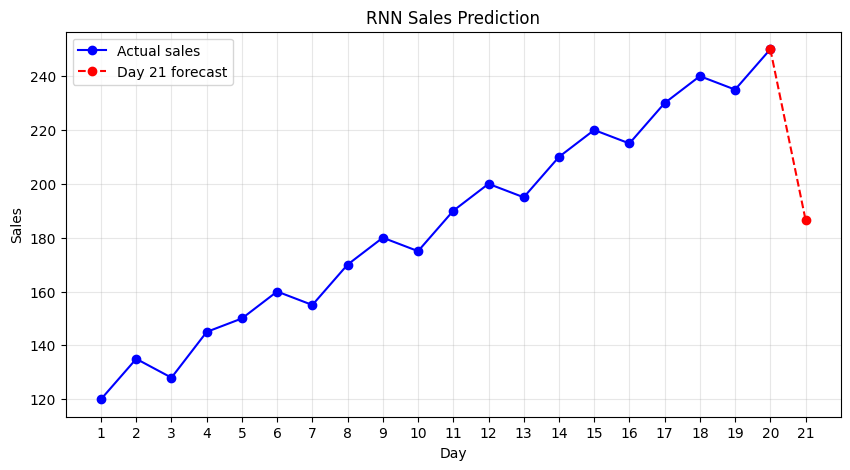

In [1]:
import numpy as np
import matplotlib.pyplot as plt
import tensorflow as tf

from sklearn.preprocessing import MinMaxScaler
from tensorflow.keras.models import Sequential
from tensorflow.keras.layers import SimpleRNN, Dense, Input

# 1. Enter sales data for 20 days
sales = np.array([
    120, 135, 128, 145, 150,
    160, 155, 170, 180, 175,
    190, 200, 195, 210, 220,
    215, 230, 240, 235, 250
], dtype=np.float32)

# 2. Validate data
if len(sales) != 20:
    raise ValueError("Enter exactly 20 sales values.")
if not np.isfinite(sales).all() or np.any(sales < 0):
    raise ValueError("Sales must be finite and non-negative.")

# 3. Normalize sales data
scaler = MinMaxScaler()
scaled = scaler.fit_transform(sales.reshape(-1, 1))

# 4. Create sequences using previous 5 days
look_back = 5
X, y = [], []

for i in range(look_back, len(scaled)):
    X.append(scaled[i-look_back:i, 0])
    y.append(scaled[i, 0])

X = np.array(X).reshape(-1, look_back, 1)
y = np.array(y)

# 5. Build RNN
tf.keras.utils.set_random_seed(42)

model = Sequential([
    Input(shape=(look_back, 1)),
    SimpleRNN(8, activation="tanh"),
    Dense(4, activation="relu"),
    Dense(1)
])

model.compile(optimizer="adam", loss="mse")

# 6. Train model
model.fit(X, y, epochs=200, batch_size=4,
          shuffle=False, verbose=0)

# 7. Predict Day 21
last_days = scaled[-look_back:].reshape(1, look_back, 1)
pred_scaled = model.predict(last_days, verbose=0)
predicted_sales = scaler.inverse_transform(pred_scaled)[0, 0]
predicted_sales = max(0, float(predicted_sales))

print("Day 20 actual sales:", sales[-1])
print("Day 21 predicted sales:", round(predicted_sales, 2))

# 8. Plot results
plt.figure(figsize=(10, 5))
plt.plot(range(1, 21), sales, "bo-", label="Actual sales")
plt.plot([20, 21], [sales[-1], predicted_sales],
         "r--o", label="Day 21 forecast")
plt.xticks(range(1, 22))
plt.xlabel("Day")
plt.ylabel("Sales")
plt.title("RNN Sales Prediction")
plt.grid(True, alpha=0.3)
plt.legend()
plt.show()

In [2]:
from google.colab import files
import pandas as pd

uploaded = files.upload()

Saving sales.csv to sales (1).csv


In [3]:
import io
import pandas as pd

filename = next(iter(uploaded))
df = pd.read_csv(io.BytesIO(uploaded[filename]))

print(df)
print("Number of sales records:", len(df))

    Day  Sales
0     1    120
1     2    135
2     3    128
3     4    145
4     5    150
5     6    160
6     7    155
7     8    170
8     9    180
9    10    175
10   11    190
11   12    200
12   13    195
13   14    210
14   15    220
15   16    215
16   17    230
17   18    240
18   19    235
19   20    250
Number of sales records: 20


Saving sales.csv to sales (2).csv
Day 20 actual sales: 250.0
Day 21 predicted sales: 186.65


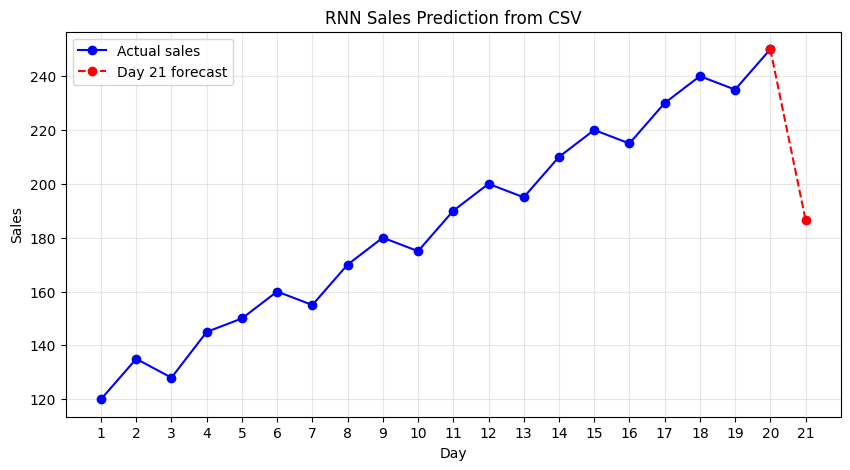

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

In [4]:
import io
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import tensorflow as tf

from google.colab import files
from sklearn.preprocessing import MinMaxScaler
from tensorflow.keras.models import Sequential
from tensorflow.keras.layers import SimpleRNN, Dense, Input

# 1. Upload CSV file
uploaded = files.upload()
if not uploaded:
    raise ValueError("Please upload a CSV file.")

filename = next(iter(uploaded))
df = pd.read_csv(io.BytesIO(uploaded[filename]))
df.columns = df.columns.str.strip()

# 2. Validate CSV
if "Sales" not in df.columns:
    raise ValueError("CSV must contain a 'Sales' column.")

df["Sales"] = pd.to_numeric(df["Sales"], errors="coerce")

if df["Sales"].isna().any():
    raise ValueError("Sales contains missing or invalid values.")

sales = df["Sales"].to_numpy(dtype=np.float32)

if len(sales) != 20:
    raise ValueError("CSV must contain exactly 20 sales values.")

if not np.isfinite(sales).all() or np.any(sales < 0):
    raise ValueError("Sales must be finite and non-negative.")

if "Day" in df.columns:
    days = pd.to_numeric(df["Day"], errors="coerce").to_numpy()
    if not np.isfinite(days).all():
        raise ValueError("Day column contains invalid values.")
    if len(np.unique(days)) != 20 or not np.all(np.diff(days) > 0):
        raise ValueError("Days must be unique and sorted ascending.")

# 3. Normalize sales
scaler = MinMaxScaler()
scaled = scaler.fit_transform(sales.reshape(-1, 1))

# 4. Prepare training sequences
look_back = 5
X, y = [], []

for i in range(look_back, len(scaled)):
    X.append(scaled[i-look_back:i, 0])
    y.append(scaled[i, 0])

X = np.array(X).reshape(-1, look_back, 1)
y = np.array(y)

# 5. Build and train RNN
tf.keras.utils.set_random_seed(42)

model = Sequential([
    Input(shape=(look_back, 1)),
    SimpleRNN(8, activation="tanh"),
    Dense(4, activation="relu"),
    Dense(1)
])

model.compile(optimizer="adam", loss="mse")
model.fit(X, y, epochs=200, batch_size=4,
          shuffle=False, verbose=0)

# 6. Predict Day 21
last_days = scaled[-look_back:].reshape(1, look_back, 1)
pred_scaled = model.predict(last_days, verbose=0)
prediction = scaler.inverse_transform(pred_scaled)[0, 0]
prediction = max(0, float(prediction))

print("Day 20 actual sales:", sales[-1])
print("Day 21 predicted sales:", round(prediction, 2))

# 7. Plot results
plt.figure(figsize=(10, 5))
plt.plot(range(1, 21), sales, "bo-", label="Actual sales")
plt.plot([20, 21], [sales[-1], prediction],
         "r--o", label="Day 21 forecast")
plt.xticks(range(1, 22))
plt.xlabel("Day")
plt.ylabel("Sales")
plt.title("RNN Sales Prediction from CSV")
plt.grid(True, alpha=0.3)
plt.legend()
plt.show()

# 8. Save prediction
pd.DataFrame({
    "Day": [21],
    "Predicted_Sales": [round(prediction, 2)]
}).to_csv("day21_prediction.csv", index=False)

files.download("day21_prediction.csv")